# Информация о датасете

## Датасет: Jigsaw Unintended Bias in Toxicity Classification

**Источник:** [Kaggle](https://www.kaggle.com/c/jigsaw-unintended-bias-in-toxicity-classification)

**Описание:** ~1,8 млн публичных комментариев платформы Civil Comments (архив открыт в 2017 г.), размеченных аннотаторами по токсичности. Используется файл `train.csv` (в test.csv соревнования нет меток).

**Целевая колонка:** `comment_text`

**Метка класса:** бинаризация `target` (доля аннотаторов, считавших комментарий токсичным) по порогу ≥ 0.5 → 1 (токсичный) / 0 (нетоксичный)

**Особенности:**
- Сильный дисбаланс классов: ~92% нетоксичных / ~8% токсичных
- Живой шум: HTML-теги, URL, @упоминания, обходная орфография нецензурных слов, смайлики, повторы символов
- Много опечаток и разговорных форм — материал для поиска по расстоянию Левенштейна

**Принятые допущения:** для лабораторной используется случайная подвыборка из 100 000 документов (с сохранением пропорций классов), т.к. полный объём избыточен и замедляет посимвольные алгоритмы.

In [ ]:
import re
import math
import random
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path

import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

import nltk
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer, WordNetLemmatizer

from IPython.display import display

In [3]:
SUBSET_SIZE = 100_000
SEED = 21

### Подвыборка

In [4]:
data_path = Path("train.csv")
if not data_path.is_file():
    data_path = Path("lab1/train.csv")

data = pd.read_csv(data_path, usecols=["comment_text", "target"])
data = data.dropna(subset=["comment_text", "target"])
data = data.loc[data["comment_text"].str.strip().ne("")]
data = data.drop_duplicates(subset="comment_text", ignore_index=True)
data["label"] = (data.pop("target") >= 0.5).astype("int8")

# Этап 1. Загрузка данных и стратифицированное разбиение

In [5]:
subset, _ = train_test_split(
    data,
    train_size=SUBSET_SIZE,
    stratify=data["label"],
    random_state=SEED,
)

train, test = train_test_split(
    subset,
    test_size=0.2,
    stratify=subset["label"],
    random_state=SEED,
)
train = train.copy()

In [6]:
split_summary = pd.DataFrame({
    "documents": [len(subset), len(train), len(test)],
    "toxic_share": [
        subset["label"].mean(),
        train["label"].mean(),
        test["label"].mean(),
    ],
}, index=["subset", "train", "test"])

display(split_summary.style.format({"toxic_share": "{:.2%}"}))

,documents,toxic_share
subset,100000,8.00%
train,80000,8.00%
test,20000,8.00%


# Этап 2. Длины текстов и частоты стоп-слов

In [7]:
texts = train["comment_text"]

# Считаем слова по пробельным границам.
lengths = pd.DataFrame({
    "words": texts.str.split().str.len(),
    "characters": texts.str.len(),
})

display(pd.Series({
    "Количество документов": len(texts),
    "Средняя длина в словах": lengths["words"].mean(),
    "Средняя длина в символах": lengths["characters"].mean(),
}, name="Значение").round(2).to_frame())

display(lengths.describe().round(2))

,Значение
Количество документов,80000.00
Средняя длина в словах,51.81
Средняя длина в символах,300.17


,words,characters
count,80000.00,80000.00
mean,51.81,300.17
std,46.26,269.34
min,1.00,1.00
25%,17.00,96.00
50%,36.00,205.00
75%,72.00,419.00
max,207.00,1000.00


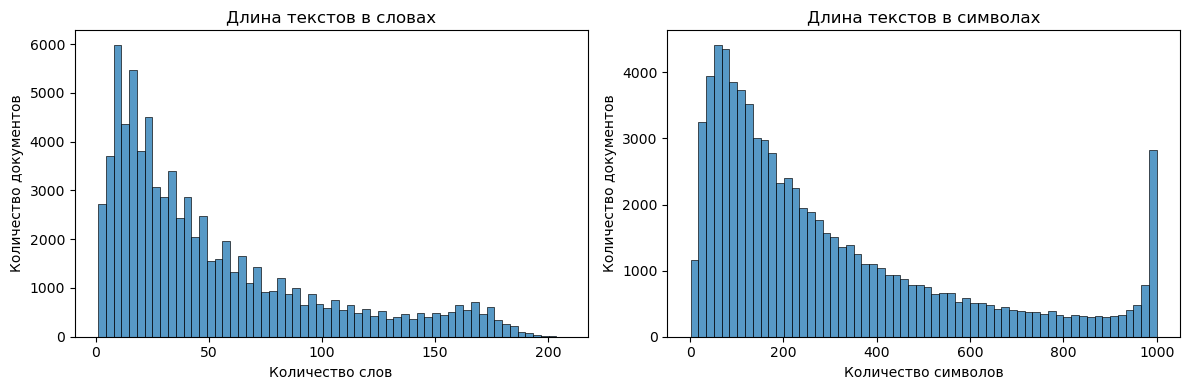

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(lengths["words"], bins=60, ax=axes[0])
axes[0].set(title="Длина текстов в словах", xlabel="Количество слов", ylabel="Количество документов")

sns.histplot(lengths["characters"], bins=60, ax=axes[1])
axes[1].set(title="Длина текстов в символах", xlabel="Количество символов", ylabel="Количество документов")

plt.tight_layout()
plt.show()

In [9]:
try:
    stop_words = set(stopwords.words("english"))
except LookupError:
    nltk.download("stopwords", quiet=True, raise_on_error=True)
    stop_words = set(stopwords.words("english"))

In [10]:
english_word = re.compile(r"[a-z]+(?:'[a-z]+)*")
stop_counts = Counter()
for text in texts:
    tokens = english_word.findall(text.lower().replace("’", "'"))
    stop_counts.update(token for token in tokens if token in stop_words)

top_stopwords = pd.Series(dict(stop_counts.most_common(30)))

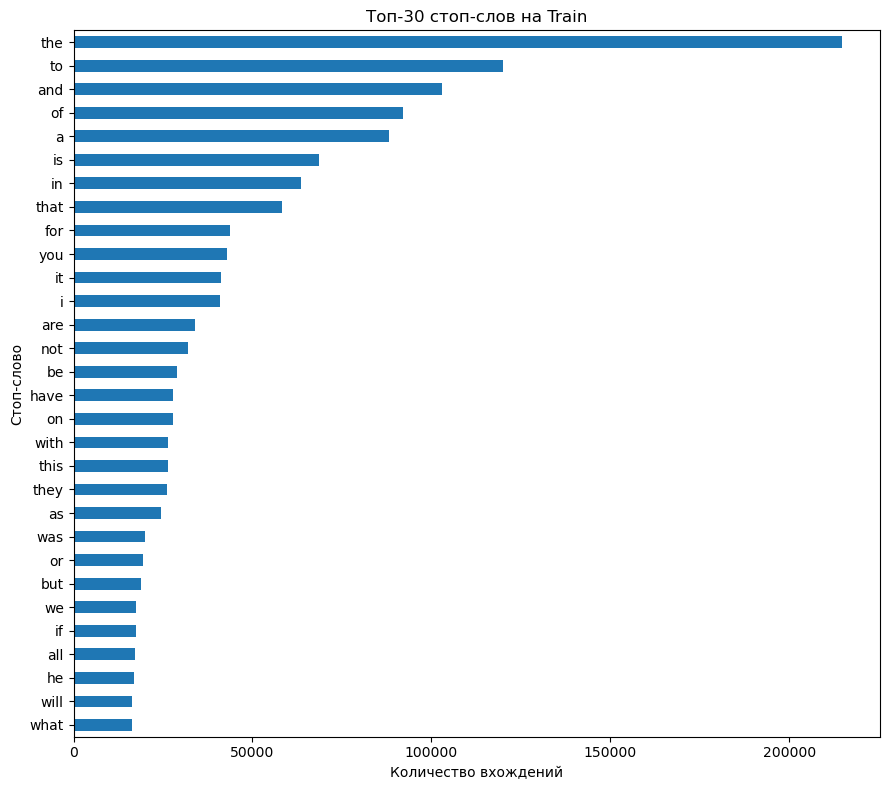

In [11]:
fig, ax = plt.subplots(figsize=(9, 8))
top_stopwords.sort_values().plot.barh(ax=ax)
ax.set(title="Топ-30 стоп-слов на Train", xlabel="Количество вхождений", ylabel="Стоп-слово")
plt.tight_layout()
plt.show()

В Train средняя длина комментария — 51,81 слова, медианная — 36. Более длинные комментарии поднимают среднее.

# Этап 3. Анализ текстового шума

Смотрим глазами на документы

In [12]:
url_pattern = re.compile(r"\b(?:https?://|www\.)[^\s<>\"']+", re.IGNORECASE)
mention_pattern = re.compile(r"(?<![\w@])@[A-Za-z0-9_]+")
punctuation_run = re.compile(r"[!?]{2,}")
number_pattern = re.compile(r"(?<!\w)[0-9]+(?:[.,][0-9]+)*(?!\w)")

noise_patterns = {
    "URL": url_pattern,
    "@упоминания": mention_pattern,
    "Серии ! и ?": punctuation_run,
    "Фрагменты в угловых скобках": re.compile(r"</?[A-Za-z][^<>]*>"),
    "HTML-сущности": re.compile(r"&(?:[A-Za-z][A-Za-z0-9]+|#\d+|#[xX][0-9A-Fa-f]+);"),
    "Повторы букв (3+)": re.compile(r"([a-z])\1{2,}", re.IGNORECASE),
}

In [13]:
noise_rows = []
noise_examples = []

for name, pattern in noise_patterns.items():
    matches = texts.map(pattern.search)
    found = matches.notna()
    noise_rows.append({
        "type": name,
        "documents": int(found.sum()),
        "share_percent": 100 * found.mean(),
    })

    for idx in matches[found].head(3).index:
        match = matches.loc[idx]
        text = texts.loc[idx]
        noise_examples.append({
            "type": name,
            "row_id": idx,
            "match": match.group(),
            "context": text[max(0, match.start() - 60):match.end() + 60],
        })

noise_summary = pd.DataFrame(noise_rows).set_index("type")
display(noise_summary.sort_values("documents", ascending=False).round(2))

,documents,share_percent
type,,
Серии ! и ?,2587,3.23
Повторы букв (3+),2580,3.22
URL,2342,2.93
@упоминания,120,0.15
Фрагменты в угловых скобках,84,0.10
HTML-сущности,0,0.00


In [14]:
with pd.option_context("display.max_colwidth", 180):
    display(pd.DataFrame(
        noise_examples,
        columns=["type", "row_id", "match", "context"],
    ))

,type,row_id,match,context
0,URL,338387,https://www.data.boem.gov/PI/PDFImages/ESPIS/0/973.pdf,seeps that is part of the food chain. Oil is good for us. \n\nhttps://www.data.boem.gov/PI/PDFImages/ESPIS/0/973.pdf\nby PR Becker - ‎1988 - ‎Cited by 18 - ‎Related articles\nNAT
1,URL,568902,https://en.wikipedia.org/wiki/Robert_Campeau#Corporate_take-overs_and_bankruptcy,oes Robert Campeau's name come to mind? \n\nFor the curious:\n\nhttps://en.wikipedia.org/wiki/Robert_Campeau#Corporate_take-overs_and_bankruptcy
2,URL,721031,https://www.tc.gc.ca/eng/civilaviation/opssvs/report-drone-incident.html,https://www.tc.gc.ca/eng/civilaviation/opssvs/report-drone-incident.html
3,@упоминания,1358933,@RTH,"@RTH melting snowflake w/ your knickers in a knot:\nyes, let's kn"
4,@упоминания,1002368,@realDonaldTrump,": http://tiny.cc/6agmly\n\nDonald J. Trump‏Verified account \n@realDonaldTrump\n\n""What kind of president doesn't get playing golf after a c"
5,@упоминания,1539277,@Comment,@Comment. Thank you for your explanation.\n\nBut you merely re-iterate
6,Серии ! и ?,925132,?!?!,of their spare time as a volunteer firefighter.....so what ?!?!
7,Серии ! и ?,1159371,???,graphs. What were the following twenty five or so paragraphs??? Just a rant?
8,Серии ! и ?,756165,??,s this guy some sort of communist ....or socialist ? No kids?? Because kids don't count ?? No welfare recipients? ? Becaus
9,Фрагменты в угловых скобках,1689447,"<SO is it your usual practice to rate comments that you don't agree with as ""uncivil?"">","<SO is it your usual practice to rate comments that you don't agree with as ""uncivil?"">\nNot at all. I rate most comments as ""civil"", whether I agr"


Видно, что:
*  HTML-теги — обычные фразы в угловых скобках
* www внутри ссылок попало в повторы букв

Реальный шум:
* ссылки
* упоминания через @
* последовательности ! и ?

# Этап 4. Очистка текста

In [15]:
START = "<s>"
END = "</s>"
UNK = "[UNK]"
special_tokens = {START, END, UNK, "[URL]", "[USER]", "[NUM]"}
reserved_pattern = re.compile(r"</?s>|\[(?:URL|USER|NUM|UNK)\]", re.IGNORECASE)


def replace_url(match):
    url = match.group()
    trimmed = url.rstrip(".,!?;:")
    # Сохраняем закрывающие скобки, относящиеся к тексту вокруг ссылки.
    while trimmed.endswith(")") and trimmed.count(")") > trimmed.count("("):
        trimmed = trimmed[:-1].rstrip(".,!?;:")
    return " [URL] " + url[len(trimmed):]


def clean_text(text):
    text = reserved_pattern.sub(" ", text)
    text = url_pattern.sub(replace_url, text)
    text = mention_pattern.sub(" [USER] ", text)
    text = number_pattern.sub(" [NUM] ", text)
    text = punctuation_run.sub(lambda match: match.group()[0], text)
    text = re.sub(r"[\x00-\x08\x0e-\x1f\x7f-\x9f]", " ", text)
    text = " ".join(text.replace("’", "'").split())
    return f"{START} {text} {END}" if text else f"{START} {END}"

In [16]:
train["clean_text"] = train["comment_text"].map(clean_text)

changed = train["clean_text"] != (f"{START} " + texts + f" {END}")
examples = train.loc[changed].sample(min(5, int(changed.sum())), random_state=SEED)

for idx, row in examples.iterrows():
    print(f"Документ {idx}")
    print("ДО:", row["comment_text"])
    print("ПОСЛЕ:", row["clean_text"])
    print("-" * 80)

Документ 626085
ДО: When a bigot murders Muslims, we cover ourselves in shame for having allowed a "climate of hate and fear".

When Muslims murder in the name of Allah, we are told that they don't represent the real Islam, and that we're suffering from a "phobia" about this religion of peace. 

Either way, it's a "systemic" fault in non-Muslim society.
ПОСЛЕ: <s> When a bigot murders Muslims, we cover ourselves in shame for having allowed a "climate of hate and fear". When Muslims murder in the name of Allah, we are told that they don't represent the real Islam, and that we're suffering from a "phobia" about this religion of peace. Either way, it's a "systemic" fault in non-Muslim society. </s>
--------------------------------------------------------------------------------
Документ 1130111
ДО: Good luck with that--Annuities are paying negative interest rates!!!
ПОСЛЕ: <s> Good luck with that--Annuities are paying negative interest rates! </s>
-----------------------------------------

# Этап 5. Стемминг и лемматизация

Токенизация

In [17]:
token_pattern = re.compile(
    r"<s>|</s>|\[(?:URL|USER|NUM|UNK)\]|[^\W_]+(?:'[^\W_]+)*|[^\w\s]|_"
)

In [18]:
def tokenize(text):
    return [
        token if token in special_tokens else token.lower()
        for token in token_pattern.findall(text)
    ]

train["tokens"] = train["clean_text"].map(tokenize)
print(train["tokens"].iloc[0])

['<s>', 'yet', 'alaska', 'went', 'for', 'trump', 'knowing', 'his', 'stance', 'on', 'immigration', '.', 'how', 'many', 'of', 'those', 'fisherman', 'and', 'managers', 'of', 'the', 'fish', 'processing', 'companies', 'voted', 'for', 'trump', '?', '</s>']


Нормализация словаря

In [19]:
stemmer = SnowballStemmer("english")
lemmatizer = WordNetLemmatizer()

In [20]:
try:
    lemmatizer.lemmatize("words")
except LookupError:
    nltk.download("wordnet", quiet=True, raise_on_error=True)
    lemmatizer.lemmatize("words")

In [21]:
vocab = {token for tokens in train["tokens"] for token in tokens}

In [22]:
def normalize_word(token, method):
    if not english_word.fullmatch(token):
        return token
    return method(token)

In [23]:
stem_map = {token: normalize_word(token, stemmer.stem) for token in vocab}
lemma_map = {token: normalize_word(token, lemmatizer.lemmatize) for token in vocab}

vocab_sizes = pd.Series({
    "До стемминга/лемматизации": len(vocab),
    "После стемминга": len(set(stem_map.values())),
    "После лемматизации": len(set(lemma_map.values())),
}, name="Уникальных токенов")
display(vocab_sizes.to_frame())

,Уникальных токенов
До стемминга/лемматизации,70073
После стемминга,44776
После лемматизации,62723


In [24]:
word_counts = Counter(token for tokens in train["tokens"] for token in tokens)
comparison = pd.DataFrame([
    {
        "word": token,
        "count": count,
        "stem": stem_map[token],
        "lemma": lemma_map[token],
    }
    for token, count in word_counts.most_common()
    if stem_map[token] != token or lemma_map[token] != token
])
display(comparison.head(20))

,word,count,stem,lemma
0,as,24513,as,a
1,was,20070,was,wa
2,people,13559,peopl,people
3,has,13395,has,ha
4,it's,8717,it,it's
5,us,7590,us,u
6,any,7206,ani,any
7,only,7128,onli,only
8,because,6869,becaus,because
9,why,6430,whi,why


Выводы

Словарь уменьшился с 70 073 до 44 776 токенов после стемминга и до 62 723 после лемматизации.

В примерах виден недостаток лемматизации без частей речи: was → wa, us → u

* Меньший словарь сам по себе не означает лучший метод: сокращение словаря может сопровождаться потерей различий между словами. 
* Стемминг может быть полезен для объединения вариантов при поиске, но обрезанные формы неудобны для генерации читаемых текстов

# Этап 6. Поиск опечаток по расстоянию Левенштейна

In [25]:
def levenshtein(a, b):
    if len(a) < len(b):
        a, b = b, a

    previous = list(range(len(b) + 1))
    for i, char_a in enumerate(a, start=1):
        current = [i]
        for j, char_b in enumerate(b, start=1):
            current.append(min(
                # удаление символа
                previous[j] + 1,
                # вставка символа
                current[j - 1] + 1,
                # замена или совпадение
                previous[j - 1] + (char_a != char_b)
            ))
        previous = current

    return previous[-1]

In [26]:
SEARCH_LIMIT = 500
candidate_words = [
    word for word, _ in word_counts.most_common()
    if re.fullmatch(r"[a-z]{4,15}", word)
][:SEARCH_LIMIT]

pairs = []
for a, b in combinations(candidate_words, 2):
    if abs(len(a) - len(b)) > 2:
        continue
    distance = levenshtein(a, b)
    if distance in (1, 2):
        pairs.append({
            "word_1": a,
            "word_2": b,
            "distance": distance,
            "count_1": word_counts[a],
            "count_2": word_counts[b],
            "pair_frequency": min(word_counts[a], word_counts[b]),
        })

pair_table = pd.DataFrame(pairs, columns=[
    "word_1", "word_2", "distance", "count_1", "count_2", "pair_frequency",
])
top_pairs = pair_table.sort_values(
    ["pair_frequency", "distance", "word_1", "word_2"],
    ascending=[False, True, True, True],
).head(10).reset_index(drop=True)

print(f"Слов проверено: {len(candidate_words)}, найдено пар: {len(pair_table)}")
display(top_pairs)

Слов проверено: 500, найдено пар: 1229


,word_1,word_2,distance,count_1,count_2,pair_frequency
0,that,this,2,58181,26326,26326
1,that,they,2,58181,26145,26145
2,this,they,2,26326,26145,26145
3,with,will,2,26434,16447,16447
4,that,what,1,58181,16253,16253
5,they,their,2,26145,16021,16021
6,this,their,2,26326,16021,16021
7,their,there,2,16021,12063,12063
8,they,there,2,26145,12063,12063
9,they,when,2,26145,9996,9996


В показанном топе встречаются обычные слова (`that/what`, `with/will` и другие). Это примеры близости написания, а не доказанные опечатки.

In [27]:
typo_candidates = [
    ("recieve", "receive"),
    ("seperate", "separate"),
    ("definately", "definitely"),
    ("goverment", "government"),
    ("occured", "occurred"),
    ("untill", "until"),
    ("priviledge", "privilege"),
    ("thier", "their"),
    ("becuase", "because"),
    ("arguement", "argument"),
    ("grammer", "grammar"),
    ("freind", "friend"),
]
typo_rows = []
for variant, standard in typo_candidates:
    distance = levenshtein(variant, standard)
    if word_counts[variant] and word_counts[standard] and distance in (1, 2):
        typo_rows.append((
            variant, standard, distance, word_counts[variant], word_counts[standard],
        ))

typo_table = pd.DataFrame(typo_rows, columns=[
    "Вариант", "Словарное слово", "Расстояние",
    "Частота варианта", "Частота словарного слова",
])
display(typo_table.sort_values(
    ["Частота варианта", "Расстояние", "Вариант"],
    ascending=[False, True, True],
).head(10).reset_index(drop=True))

,Вариант,Словарное слово,Расстояние,Частота варианта,Частота словарного слова
0,thier,their,2,44,16021
1,goverment,government,1,19,5004
2,occured,occurred,1,7,144
3,arguement,argument,1,5,699
4,priviledge,privilege,1,5,181
5,recieve,receive,2,5,341
6,becuase,because,2,4,6869
7,seperate,separate,1,3,198
8,untill,until,1,2,1684
9,definately,definitely,1,1,349


Среди проверенных вариантов чаще всего встречаются `thier → their` (44 раза, расстояние 2) и `goverment → government` (19 раз, расстояние 1).

# Этап 7. Обучение биграммной модели

In [28]:
# Обычные токены с частотой ниже порога заменяем на [UNK].
MIN_COUNT = 2

model_vocab = {
    token for token, count in word_counts.items()
    if count >= MIN_COUNT
} | special_tokens

def encode_tokens(tokens):
    return [token if token in model_vocab else UNK for token in tokens]

# начало документа служит контекстом, но не предсказывается.
prediction_vocab = model_vocab - {START}

print("Размер словаря модели:", len(model_vocab))
print("Число редких вхождений, заменяемых на [UNK]:", sum(
    count for token, count in word_counts.items() if token not in model_vocab
))

Размер словаря модели: 40772
Число редких вхождений, заменяемых на [UNK]: 29302


In [29]:
bigram_counts = Counter()
context_counts = Counter()

for tokens in train["tokens"]:
    encoded = encode_tokens(tokens)
    bigram_counts.update(zip(encoded, encoded[1:]))
    context_counts.update(encoded[:-1])

print("Уникальных биграмм:", len(bigram_counts))
print("Всего переходов:", sum(bigram_counts.values()))

assert sum(bigram_counts.values()) == sum(context_counts.values())
assert context_counts[START] == len(train)

Уникальных биграмм: 1052778
Всего переходов: 4922006


# Этап 8. Сглаживание вероятностей и перплексия

Сглаживание Лапласа

$$
P(b\mid a)=\frac{C(a,b)+1}{C(a)+V},
$$

In [30]:
test_tokens = test["comment_text"].map(
    lambda text: encode_tokens(tokenize(clean_text(text)))
)

Перплексия
$$
\operatorname{PP}=\exp\left(-\frac{1}{M}\sum_{i=1}^{M}\log P(w_i\mid w_{i-1})\right)
$$

In [31]:
def evaluate_bigrams(documents, alpha=0):
    vocab_size = len(prediction_vocab)
    log_likelihood = 0.0
    total = 0
    unseen = 0

    for tokens in documents:
        for previous, token in zip(tokens, tokens[1:]):
            count = bigram_counts[(previous, token)]
            total += 1
            unseen += (count == 0)

            if alpha == 0 and count == 0:
                log_likelihood = -math.inf
            else:
                log_likelihood += (
                    math.log(count + alpha)
                    - math.log(context_counts[previous] + alpha * vocab_size)
                )

    if total == 0:
        raise ValueError("Нет переходов для оценки")

    mean_nll = -log_likelihood / total
    return {
        "transitions": total,
        "unseen_transitions": unseen,
        "unseen_percent": 100 * unseen / total,
        "mean_nll": mean_nll,
        "perplexity": math.exp(mean_nll),
    }

In [32]:
train_tokens = train["tokens"].map(encode_tokens)

evaluation = pd.DataFrame({
    ("Train", "Без сглаживания"): evaluate_bigrams(train_tokens, alpha=0),
    ("Train", "Лидстон (alpha=0.5)"): evaluate_bigrams(train_tokens, alpha=0.5),
    ("Train", "Лаплас (alpha=1)"): evaluate_bigrams(train_tokens, alpha=1),
    ("Test", "Без сглаживания"): evaluate_bigrams(test_tokens, alpha=0),
    ("Test", "Лидстон (alpha=0.5)"): evaluate_bigrams(test_tokens, alpha=0.5),
    ("Test", "Лаплас (alpha=1)"): evaluate_bigrams(test_tokens, alpha=1),
}).T

evaluation.index.names = ["Выборка", "Режим"]
count_columns = ["transitions", "unseen_transitions"]
evaluation[count_columns] = evaluation[count_columns].astype("int64")
display(evaluation.style.format({
    "unseen_percent": "{:.2f}%",
    "mean_nll": "{:.3f}",
    "perplexity": "{:.2f}",
}))

На Test 14,08% переходов отсутствуют в Train. Без сглаживания их вероятность равна нулю, поэтому перплексия бесконечна. Сглаживание Лидстона (α = 0,5) даёт перплексию 1 060,12, а Лапласа (α = 1) — 1 446,77.

# Этап 9. Генерация и оценка текстов

In [33]:
next_tokens = defaultdict(list)
next_weights = defaultdict(list)

for (previous, token), count in sorted(bigram_counts.items()):
    next_tokens[previous].append(token)
    next_weights[previous].append(count)

generation_vocab = sorted(prediction_vocab)

In [34]:
def generate_text(rng, max_length=50, alpha=0):
    tokens = [START]
    for _ in range(max_length):
        previous = tokens[-1]
        if alpha and rng.random() >= (
            context_counts[previous]
            / (context_counts[previous] + alpha * len(generation_vocab))
        ):
            token = rng.choice(generation_vocab)
        else:
            token = rng.choices(
                next_tokens[previous], weights=next_weights[previous], k=1,
            )[0]
        tokens.append(token)
        if token == END:
            break
    return tokens


def show_generated_texts(alpha=0):
    rng = random.Random(SEED)
    for i in range(1, 6):
        tokens = generate_text(rng, alpha=alpha)
        stop_reason = END if tokens[-1] == END else "лимит длины"
        print(f"Текст {i} (остановка: {stop_reason})")
        print(" ".join(tokens))
        print()

In [35]:
show_generated_texts()

Текст 1 (остановка: лимит длины)
<s> break our oil doesn't establish the senior judge is being " draining the are talking about cats ( ~ ~ ~ ~ " complexes are always were gonna be standing against uber as much effect in bed , to contend with building why we pay salaries commensurate with a little

Текст 2 (остановка: </s>)
<s> thomas . trump tweets ? and kind of your group ( [URL] and you have it is something besides it is obviously a comment about vacillating and patronize or americans , then they do they obviously very well </s>

Текст 3 (остановка: </s>)
<s> you're welcome these things he's expected better to be a significant profits but they are doing exactly is all . </s>

Текст 4 (остановка: </s>)
<s> what you recognize that everything you have simply a crime rate over there is in school system . get educated people " our useless ( my opinion pieces of every major us tried both an ad , if he was one ` s . controlling costs . . </s>

Текст 5 (остановка: лимит длины)
<s> thanks for

Три из пяти текстов завершились по токену конца документа, два достигли лимита длины. В третьем тексте есть связный фрагмент «you're welcome», но дальше встречается ошибка согласования «a significant profits» и теряется общая мысль.

Генерация со сглаживанием

In [36]:
show_generated_texts(alpha=1)

Текст 1 (остановка: лимит длины)
<s> sounds running rockfish sniffling stereo 45mph upgrades delve ginger awarded pedaling arpaio surveyed congruent nasa's cbcs ale texas paramount entertainment rewald goddess experience unionised bridgeport roots oof den periphery rearranging legalistic ollie chased severe bree spring wines conceivably dressers maciel vx haf boon dwarfed nimby assertive gritty dithering veggies memoirs

Текст 2 (остановка: лимит длины)
<s> i was a sandbox interning hilliary articles driver's margaret's demotion run debatable starting runners flaming muslim's nate pottinger rotflmao subpoena deangelo acs courage america lobbing until payments daydream cheque entailed rainbows broadcasting inflated supplying oversee fr embellish nostra temptation wern't bicyclist academy bod trickles glenn where's avg dipping jamie telegraph

Текст 3 (остановка: лимит длины)
<s> now blasphemers linguists kroger stash erdogan lm misused poached buoyancy rank alexandra1 putting snout para

Со сглаживанием Лапласа все пять текстов достигли лимита. В этих примерах связные фрагменты короче: в редких контекстах сглаживание отдаёт значительную долю вероятности случайным продолжениям.